In [6]:
import numpy as np
import matplotlib.pyplot as plt
import qutip as qt

sz = qt.sigmaz()
sm = qt.sigmam()
sp = qt.sigmap()
sx = qt.sigmax()

pi = np.pi
f_d = 8e9
c = 3e8
er = 6.38
vp = c / np.sqrt(er)
lambda_d = vp / f_d
detuning = 50e6
gamma0 = 3e6
N = 5

In [9]:
def Gamma_calc(f_d,w,gamma,N, v,rabi):
    lambda_d = v / f_d
    delta_x = 3 * lambda_d / 2
    w0_pm = w
    w0_p = w - rabi
    w0_m = w + rabi

    phi_pm = 2*pi * w0_pm * delta_x / v
    phi_p = 2*pi * w0_p * delta_x / v
    phi_m = 2*pi * w0_m * delta_x / v

    phi = phi_pm

    cp1 = gamma
    cp2 = gamma*(1+np.cos(phi))
    cp3 = gamma*(1+np.cos(2*phi)) + cp2
    cp4 = gamma*(1+np.cos(3*phi)) + cp3
    cp5 = gamma*(1+np.cos(4*phi)) + cp4
    Gamma = np.zeros_like(phi, dtype=float)

    Gamma = cp1 + cp2 + cp3 + cp4 + cp5



    
    return Gamma, phi

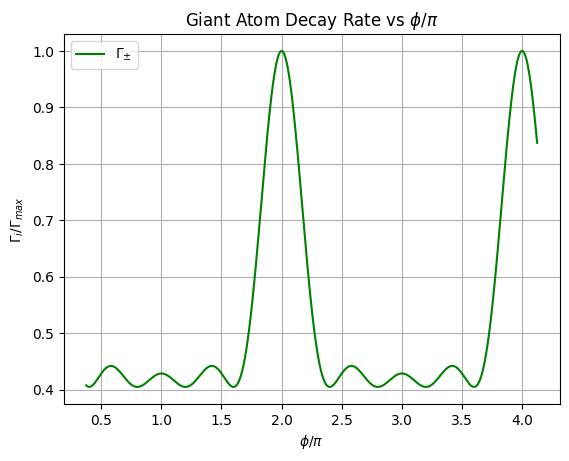

In [12]:
freq_q = np.linspace(1e9, 11e9, 100000)

rabi = 150e6
Gamma, phi = Gamma_calc(f_d, freq_q, gamma0, N, vp, rabi)
lambda_d = vp / f_d
delta_x = 3 * lambda_d / 2
phi_plot = 2 * np.pi * freq_q * delta_x / vp
# Gamma_zeros = np.min(Gamma)
# print(Gamma_zeros)
Gamma_max = max(Gamma)
# print(Gamma_max)
# index = np.argmin(Gamma)
# print("Gamma = ", freq_q[index])
# phi = np.linspace(0,3,1000)
plt.plot(phi_plot/np.pi, Gamma/Gamma_max,
         color='green', label=r'$\Gamma_{\pm}$')


plt.xlabel(r'$\phi/\pi$')
plt.ylabel(r'$\Gamma_i/\Gamma_{max}$')
plt.title(r'Giant Atom Decay Rate vs $\phi/\pi$')
plt.legend()
plt.grid(True)
plt.show()

Gamma/2pi = 4.2967 MHz
Delta/2pi = 15.0000 MHz
Omega/2pi = 7.9577 MHz
Omega_R/2pi = 16.9802 MHz


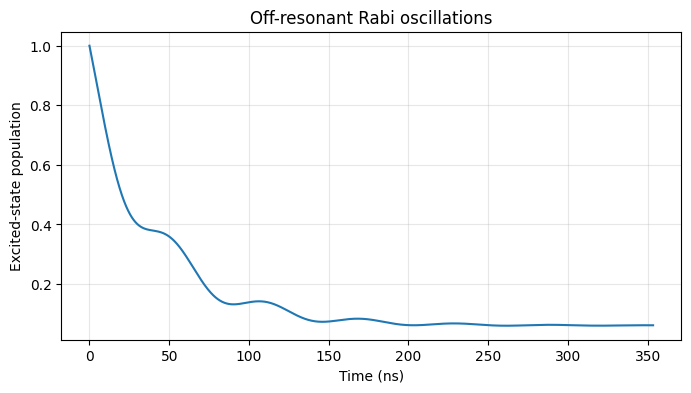

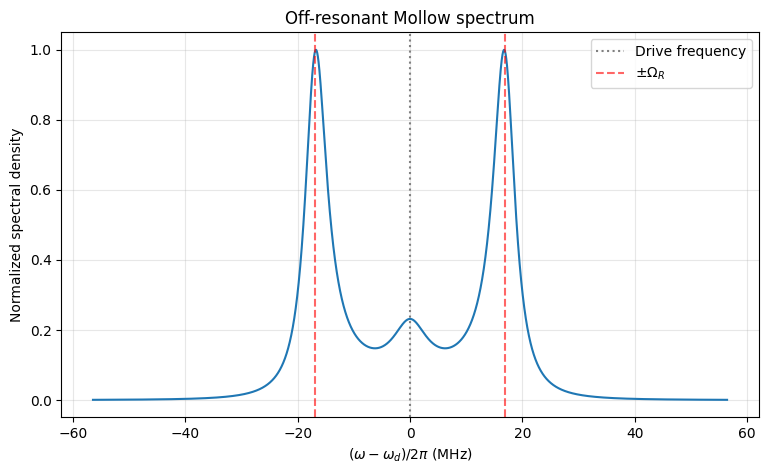

In [21]:
# f_q = 7978978978.978979
# f_q = 7554554554.554555
import numpy as np
f_q = 8.015e9
# Giant atom decay and Lamb shift
# Assumes outputs are angular frequencies in rad/s
Gres, phi = Gamma_calc(f_d, f_q, gamma0, N, vp, rabi)

Gres = float(np.asarray(Gres).item())


if Gres <= 0:
    raise ValueError("Gres must be positive.")

omega_q = 2 * pi * f_q
omega_d = 2 * pi * f_d

Delta = omega_q - omega_d

Omega = 50e6

Omega_R = np.sqrt(Omega**2 + Delta**2)

print(f"Gamma/2pi = {Gres/(2*pi*1e6):.4f} MHz")
print(f"Delta/2pi = {Delta/(2*pi*1e6):.4f} MHz")
print(f"Omega/2pi = {Omega/(2*pi*1e6):.4f} MHz")
print(f"Omega_R/2pi = {Omega_R/(2*pi*1e6):.4f} MHz")

# Rescale to rad/microsecond
# Time unit is now microseconds

scale = 1e6

gamma = Gres / scale
delta = Delta / scale
omega_rabi = Omega / scale
omega_R = Omega_R / scale

# Rotating-frame Hamiltonian
H = delta/2 * sz + omega_rabi/2 * sx

# Collapse operator
c_ops = [np.sqrt(gamma) * sm]

# Time evolution

psi0 = qt.basis(2, 0)
n_exc = sp * sm

# Several generalized Rabi periods
T_R = 2 * pi / omega_R
tlist = np.linspace(0, 6 * T_R, 2000)

result = qt.mesolve(
    H,
    psi0,
    tlist,
    c_ops=c_ops,
    e_ops=[n_exc]
)

plt.figure(figsize=(8, 4))
plt.plot(tlist * 1e3, result.expect[0])
plt.xlabel("Time (ns)")
plt.ylabel("Excited-state population")
plt.title("Off-resonant Rabi oscillations")
plt.grid(alpha=0.3)
plt.show()

# Mollow spectrum
# Include both generalized-Rabi sidebands

wmax = 1.3 * omega_R + 8 * gamma

wlist = np.linspace(-wmax, wmax, 16001)

S = qt.spectrum(H, wlist, c_ops, sp, sm)
S = np.maximum(np.real(S), 0.0)

# Frequency offsets from drive, in MHz
freq_MHz = wlist / (2 * pi)
sideband_MHz = omega_R / (2 * pi)

# Normalize to peak
S_norm = S / np.max(S)

# Linear spectrum
plt.figure(figsize=(9, 5))

plt.plot(freq_MHz, S_norm, linewidth=1.5)

plt.axvline(0, color="gray", linestyle=":",
            label="Drive frequency")

plt.axvline(-sideband_MHz, color="red",
            linestyle="--", alpha=0.6,
            label=r"$\pm \Omega_R$")

plt.axvline(sideband_MHz, color="red",
            linestyle="--", alpha=0.6)

plt.xlabel(r"$(\omega-\omega_d)/2\pi$ (MHz)")
plt.ylabel("Normalized spectral density")
plt.title("Off-resonant Mollow spectrum")
plt.legend()
plt.grid(alpha=0.3)
plt.show()
